# The proposed Section 301 excess-capacity tariffs: what they would do

On **November 25, 2026** USTR made determinations in 14 of its 16 Section 301
investigations of *structural excess capacity and production in manufacturing sectors*
(initiated March 11, 2026) and **proposed** additional tariffs on each economy: China, the
European Union, Japan, Korea, Switzerland, Taiwan, Bangladesh, Cambodia, Indonesia,
Malaysia, Thailand, India, Singapore and Vietnam. It made no determination for Mexico or
Norway.

**Nothing is in force.** Every rate is "up to", there is no effective date and no chapter
99 heading. Comments are due January 5, 2027 and the hearing is January 25, 2027. The
published series nonetheless carries the proposals from an **assumed** date, February 1,
2027, at the rates as written, to show where rates are headed. Rows before that date are
unaffected. This notebook asks what the tariff rates would be **if the proposals took
effect as written**, by economy and for the national average, and how much the answer
depends on the choices the notices leave open.

Each proposed rate is "net of existing Section 301 tariffs": the forced-labor duty already
in place counts toward it. The new duty tops each product up to a cap rather than adding a
fixed amount, which the engine models as a Phase 4 cap regime.

All numbers come from the same engine as the published tracker, evaluated at today's rates
(October 30, 2026, the latest policy date in force) with the proposed action added. National averages include the flat
2.3 point pre-2025 baseline.

In [1]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [2]:
%matplotlib inline
import json, io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [3]:
figfile = "./figures/"
os.makedirs(figfile, exist_ok=True)

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 2, 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
    'axes.titlesize': 18, 'axes.labelsize': 16,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.frameon': False, 'legend.fontsize': 12,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'savefig.bbox': 'tight',
})

PALETTE = {
    'now':         'black',      # today's law
    'proposed':    'darkblue',   # the proposal as written
    'agreement':   'darkgreen',  # rates tied to an agreement (India, Singapore, Vietnam)
    'alternative': '#8B0000',    # the stated higher alternatives
    'ieepa':       '#8A8A8A',    # the last IEEPA-era rates (Feb 7, 2026)
}

WEIGHT_YEAR  = 2024
MFN_BASELINE = 2.3               # flat baseline added to the NATIONAL headline only
published    = pd.read_csv('country-by-time.csv', parse_dates=['date'])
AS_OF        = pd.Timestamp('2026-10-30')       # today's rates: the latest policy date in force on Nov 25, 2026
IEEPA_DATE   = pd.Timestamp('2026-02-07')       # last policy date before the Supreme Court ruling
print("rates evaluated as of", AS_OF.date())

rates evaluated as of 2026-10-30


## Load the tariff engine

Execute the main notebook's code cells up to `tariff_imports`. Its registry carries the
proposed action from the assumed date, February 1, 2027. Everything here is evaluated at
October 30, 2026, before that date, so the baseline is today's law and each scenario adds
its own copy of the action, in force at the evaluation date.

In [4]:
_nb = json.load(io.open('code/make-tariff-by-country-by-time.ipynb', encoding='utf-8'))
for _cell in _nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break
print(f"engine loaded: {len(TARIFF_ACTIONS)} actions in force, scheduled or assumed, "
      f"SECP_301_LIVE = {SECP_301_LIVE}, assumed date {SECP_301_EFFECTIVE_DATE}")

engine loaded: 103 actions in force, scheduled or assumed, SECP_301_LIVE = True, assumed date 2027-02-01


## What was proposed

One row per economy, from `tariff-lists/301-secp-economies.csv`. The **proposed** rate is
the one each notice puts forward. India, Singapore and Vietnam also carry a lower rate tied
to a responsive **agreement**; the other eleven carry a higher **alternative** if
consultations prove unsatisfactory. For the EU, Japan, Korea, Switzerland and Taiwan the
rate is also net of the product's MFN duty.

In [5]:
_labor = pd.read_csv('./tariff-lists/301-labor-economies-FINAL.csv', dtype={'cty_code': str})
_tier = dict(zip(_labor.cty_code, _labor.proposed_rate_pct))

P = secp_econ[['economy', 'cty_code', 'proposed_rate_pct', 'agreement_rate_pct',
               'alternative_rate_pct', 'net_of_mfn', 'exempt_232']].copy()
P.insert(2, 'labor_301_now', P.cty_code.map(_tier))
P['part_II_codes'] = P.cty_code.map(
    secp_annex[secp_annex.part == 'II'].groupby('cty_code').size()).fillna(0).astype(int)
P.columns = ['Economy', 'Code', 'Labor 301 now', 'Proposed', 'With agreement', 'Alternative',
             'Net of MFN', '232 goods exempt', 'Country-specific exemptions']
print(P.drop(columns='Code').to_string(index=False))
print("\nChina: 20% applies to goods outside the annexes; Annex A goods (the list the labor duty "
      "exempts) pay up to 10%;\nAnnex B, the 77-code 30-for-30 list, is exempt. "
      "China's notice does not mention Section 232.")

       Economy  Labor 301 now Proposed With agreement Alternative Net of MFN 232 goods exempt  Country-specific exemptions
         China           12.5     20.0                       40.0      False            False                            0
European Union           10.0     15.0                       20.0       True             True                           45
         Japan           12.5     15.0                       20.0       True             True                            0
   South Korea           12.5     15.0                       25.0       True             True                            0
   Switzerland           12.5     15.0                       20.0       True             True                          134
        Taiwan           10.0     15.0                       25.0       True             True                          118
    Bangladesh           10.0     18.0                       20.0      False             True                           87
      Cambodia  

## Build the scenarios

Each scenario is the engine run with today's registry plus the proposed cap regimes, passed
through `tariff_imports(..., actions=...)`. The registry itself is never edited.

| key | rates | China's Section 232 goods |
|-----|-------|---------------------------|
| `base` | today's law | n/a |
| `proposed` | as written | covered, as written |
| `agreement` | India 17, Singapore 10, Vietnam 20; others as written | covered |
| `alternative` | every stated higher alternative (China 40 on all goods) | covered |
| `*_c232` | the same three | carved out, as for the other 13 economies |
| `korea_net` | as written, Korea's top-up netted against MFN | covered |
| `no_lists` | as written, country-specific exemptions ignored | covered |

In [6]:
_cache = {}
def _imp(cty):
    if cty not in _cache:
        _cache[cty] = load_imports(cty, year=WEIGHT_YEAR)
    return _cache[cty].copy()

_RATE = country_list.set_index('CTY_CODE')['rtariff-aug'].to_dict()

def lines(cty, actions=None, date=None):
    # HS10 lines for one partner under an action list (None = today's registry)
    return tariff_imports(_imp(cty), cty, _RATE[cty], pd.Timestamp(date or AS_OF), actions=actions)

def rate(cty, actions=None, date=None):
    r = lines(cty, actions, date)
    return (r['tariff'] * r['share']).sum()

SCENARIOS = {
    'proposed':         dict(),
    'agreement':        dict(rates='agreement'),
    'alternative':      dict(rates='alternative'),
    'proposed_c232':    dict(china_exempt_232=True),
    'agreement_c232':   dict(rates='agreement', china_exempt_232=True),
    'alternative_c232': dict(rates='alternative', china_exempt_232=True),
    'korea_net':        dict(korea_net_of_mfn=True),
    'no_lists':         dict(country_lists=False),
}
ACTIONS = {k: TARIFF_ACTIONS + secp_actions(effective_date=str(AS_OF.date()), **kw)
           for k, kw in SCENARIOS.items()}
n_registry = len(TARIFF_ACTIONS)

TARGETS = dict(zip(secp_econ.cty_code, secp_econ.economy))
rows = []
for _, c in country_list.iterrows():
    code = c['CTY_CODE']
    base = rate(code)
    row = dict(code=code, name=c['CTY_NAME'].title(), imports=_imp(code)['imports'].sum() / 1e9,
               targeted=code in TARGETS, base=base)
    for k in SCENARIOS:
        row[k] = rate(code, ACTIONS[k]) if code in TARGETS else base
    rows.append(row)
S = pd.DataFrame(rows)
S['name'] = S['name'].replace({'Korea, South': 'Korea', 'European Union': 'European Union'})

def natl(col):
    return (S[col] * S['imports']).sum() / S['imports'].sum() + MFN_BASELINE

NAT = {k: natl(k) for k in ['base'] + list(SCENARIOS)}

# Guards: the baseline is the published series, and scenarios leave the registry alone.
_pub = published[published.date == AS_OF].set_index('country_name')['effective tariff']
assert np.allclose(S.set_index(S['code'].map(dict(zip(country_list.CTY_CODE, country_list.CTY_NAME))))['base'],
                   _pub.reindex(country_list.CTY_NAME).values, atol=1e-9), "baseline != country-by-time.csv"
_daily = pd.read_csv('daily-tariff-latest-data.csv', parse_dates=['date']).set_index('date')
assert abs(NAT['base'] - _daily.loc[AS_OF, 'import_weighted_avg_tariff']) < 1e-9
assert len(TARIFF_ACTIONS) == n_registry
# The registry's own copy of the action must not be in force at the evaluation date.
assert not SECP_301_LIVE or AS_OF < pd.Timestamp(SECP_301_EFFECTIVE_DATE)
assert np.allclose(S.loc[~S.targeted, 'proposed'], S.loc[~S.targeted, 'base'])

print(f"National average tariff, incl. the {MFN_BASELINE} pt baseline (2024 weights)")
for k, lab in [('base', 'today'), ('proposed', 'proposed, as written'),
               ('agreement', 'with India, Singapore, Vietnam agreements'),
               ('alternative', 'every stated alternative')]:
    step = '' if k == 'base' else f"  ({NAT[k] - NAT['base']:+.2f} pts)"
    print(f"  {lab:44s} {NAT[k]:6.2f}%{step}")
print(f"\n14 targeted economies: ${S.loc[S.targeted, 'imports'].sum():,.0f}B of "
      f"${S['imports'].sum():,.0f}B panel imports "
      f"({100 * S.loc[S.targeted, 'imports'].sum() / S['imports'].sum():.1f}%)")

National average tariff, incl. the 2.3 pt baseline (2024 weights)
  today                                         11.46%
  proposed, as written                          14.36%  (+2.89 pts)
  with India, Singapore, Vietnam agreements     13.83%  (+2.37 pts)
  every stated alternative                      18.39%  (+6.92 pts)

14 targeted economies: $1,921B of $3,209B panel imports (59.9%)


# The national average

As written, the proposals would lift the average tariff by about 2.9 points, back to where
it stood on the eve of the Supreme Court's IEEPA ruling. The bars take China's
notice as written: unlike the other 13, it does not exempt goods already under Section
232, so the China duty covers them. What a carve-out would change is shown under *What
the result depends on*.

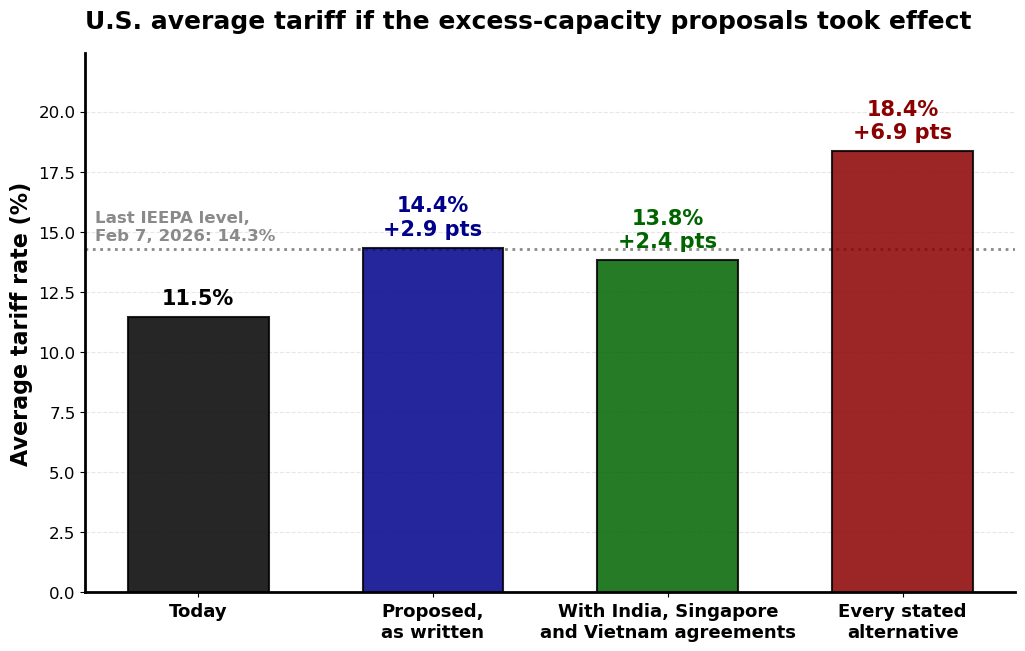

proposed     14.36%  (+2.89)
agreement    13.83%  (+2.37)
alternative  18.39%  (+6.92)
last IEEPA level (Feb 7, 2026): 14.28%


In [7]:
ieepa_nat = _daily.loc[IEEPA_DATE, 'import_weighted_avg_tariff']
order  = ['base', 'proposed', 'agreement', 'alternative']
labels = ['Today', 'Proposed,\nas written', 'With India, Singapore\nand Vietnam agreements',
          'Every stated\nalternative']
colors = [PALETTE['now'], PALETTE['proposed'], PALETTE['agreement'], PALETTE['alternative']]
vals   = [NAT[k] for k in order]

fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(order))
bars = ax.bar(x, vals, color=colors, width=0.6, zorder=3, alpha=0.85,
              edgecolor='black', linewidth=1.5)
for b, v, col in zip(bars, vals, colors):
    step = '' if v == NAT['base'] else f"\n{v - NAT['base']:+.1f} pts"
    ax.annotate(f'{v:.1f}%{step}', (b.get_x() + b.get_width() / 2, v), xytext=(0, 6),
                textcoords='offset points', ha='center', va='bottom', fontsize=15,
                fontweight='bold', color=col)
ax.axhline(ieepa_nat, color=PALETTE['ieepa'], lw=2, ls=':', zorder=2)
ax.text(-0.44, ieepa_nat + 0.25, f"Last IEEPA level,\nFeb 7, 2026: {ieepa_nat:.1f}%",
        fontsize=12, fontweight='bold', color=PALETTE['ieepa'], va='bottom', ha='left')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=13)
for lab in ax.get_xticklabels():
    lab.set_fontweight('bold')
ax.set_ylabel('Average tariff rate (%)')
ax.set_ylim(0, max(vals) * 1.22)
ax.set_title('U.S. average tariff if the excess-capacity proposals took effect',
             loc='left', pad=18)
ax.grid(axis='y')
plt.savefig(figfile + 'secp-national.png')
plt.savefig(figfile + 'secp-national.pdf')
plt.show()

for k in order[1:]:
    print(f"{k:12s} {NAT[k]:.2f}%  ({NAT[k]-NAT['base']:+.2f})")
print(f"last IEEPA level (Feb 7, 2026): {ieepa_nat:.2f}%")

# By economy

The proposals are far from uniform. For the five economies with framework deals and a
rate net of MFN (the EU, Japan, Korea, Switzerland, Taiwan) the all-in cap rises only from
10 or 12.5 to 15, so the step is small. For the South and Southeast Asian exporters the cap
rises to 18, and for Vietnam and India to 35 and 25 unless they reach agreements.

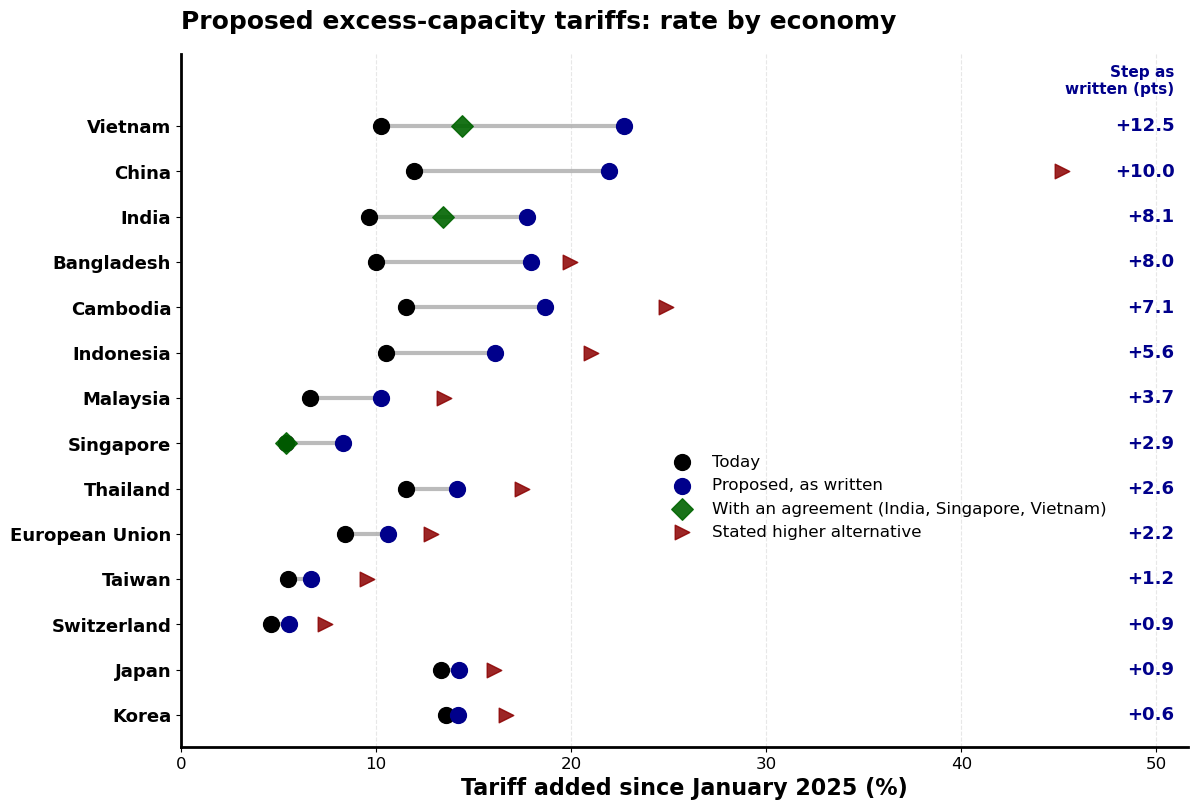

       economy  imports $B  labor 301  proposed cap  rate now  rate proposed     step  step w/ agreement  step alternative  pts of national step
       Vietnam      141.36      12.50         35.00     10.25          22.71    12.46               4.15             12.46                  0.55
         China      429.43      12.50         20.00     11.94          21.95    10.01              10.01             33.21                  1.34
         India       87.74      10.00         25.00      9.65          17.73     8.08               3.77              8.08                  0.22
    Bangladesh        8.44      10.00         18.00     10.00          17.96     7.97               7.97              9.96                  0.02
      Cambodia       12.73      10.00         18.00     11.55          18.66     7.11               7.11             13.33                  0.03
     Indonesia       28.11      10.00         18.00     10.50          16.11     5.60               5.60             10.51        

In [8]:
T = S[S.targeted].copy()
for k in ('proposed', 'agreement', 'alternative'):
    T['d_' + k] = T[k] - T['base']
T['contrib'] = T['d_proposed'] * T['imports'] / S['imports'].sum()
T = T.sort_values('d_proposed').reset_index(drop=True)
has_agreement = set(secp_econ.loc[secp_econ.agreement_rate_pct != '', 'cty_code'])

y = np.arange(len(T))
fig, ax = plt.subplots(figsize=(13, 9))
ax.hlines(y, T['base'], T['proposed'], color='#BBBBBB', lw=3, zorder=1)
ax.scatter(T['base'], y, s=130, color=PALETTE['now'], zorder=5, label='Today')
ax.scatter(T['proposed'], y, s=130, color=PALETTE['proposed'], zorder=5, label='Proposed, as written')
_a = T[T.code.isin(has_agreement)]
ax.scatter(_a['agreement'], _a.index, s=120, marker='D', color=PALETTE['agreement'], alpha=0.9,
           zorder=6, label='With an agreement (India, Singapore, Vietnam)')
_h = T[~T.code.isin(has_agreement)]          # the other eleven carry a higher alternative
ax.scatter(_h['alternative'], _h.index, s=110, marker='>', color=PALETTE['alternative'], alpha=0.85,
           zorder=3, label='Stated higher alternative')
xmax = max(T['alternative'].max(), T['proposed'].max()) * 1.04
for yi, d in zip(y, T['d_proposed']):
    ax.text(xmax * 1.085, yi, f'{d:+.1f}', ha='right', va='center', fontsize=13,
            fontweight='bold', color=PALETTE['proposed'])
ax.text(xmax * 1.085, len(T) - 0.35, 'Step as\nwritten (pts)', ha='right', va='bottom',
        fontsize=11, fontweight='bold', color=PALETTE['proposed'])
ax.set_yticks(y); ax.set_yticklabels(T['name'], fontsize=13)
for lab in ax.get_yticklabels():
    lab.set_fontweight('bold')
ax.set_xlim(0, xmax * 1.10)
ax.set_ylim(-0.7, len(T) + 0.6)
ax.set_xlabel('Tariff added since January 2025 (%)')
ax.set_title('Proposed excess-capacity tariffs: rate by economy', loc='left', pad=18)
ax.legend(loc='center', bbox_to_anchor=(0.70, 0.36), fontsize=12)
ax.grid(axis='x')
plt.savefig(figfile + 'secp-by-economy.png')
plt.savefig(figfile + 'secp-by-economy.pdf')
plt.show()

tab = T.sort_values('d_proposed', ascending=False)
caps = secp_econ.set_index('cty_code')
tab['labor'] = tab.code.map(_tier)
tab['cap'] = tab.code.map(caps.proposed_rate_pct).astype(float)
show = tab[['name', 'imports', 'labor', 'cap', 'base', 'proposed', 'd_proposed',
            'd_agreement', 'd_alternative', 'contrib']]
show.columns = ['economy', 'imports $B', 'labor 301', 'proposed cap', 'rate now', 'rate proposed',
                'step', 'step w/ agreement', 'step alternative', 'pts of national step']
print(show.to_string(index=False, float_format=lambda v: f'{v:8.2f}'))
print(f"\nnational step as written: {NAT['proposed'] - NAT['base']:+.2f} pts  "
      f"(sum of contributions {tab['contrib'].sum():+.2f})")

### China

China's step has three parts, and the largest uncertainty in the whole exercise sits in one
of them. Goods outside the annexes are topped up from the 12.5% labor duty to 20%. Annex A
goods, which the labor duty exempts, start paying 10%. And Section 232 goods, which the
labor duty also exempts, would pay the full 20% on top of their Section 232 rate if the
notice is read as written.

In [9]:
b, p = lines('5700'), lines('5700', ACTIONS['proposed'])
m232 = (_mask_all_232(b) & ~_mask_annex_II_removed(b)).to_numpy()
inA  = _mask_stacked_include(b, 'SECP-301-China-AnnexA').to_numpy()
inB  = _mask_stacked_exempt(b, 'China-30for30').to_numpy()
add  = (p['tariff'] - b['tariff']).to_numpy()
sh   = b['share'].to_numpy()
groups = {
    'Section 232 goods (as written: 20%, or 10% if in Annex A)': m232,
    'Annex A goods, exempt from the labor duty (up to 10%)':     inA & ~m232 & ~inB,
    'Annex B, the 30-for-30 list (exempt)':                      inB & ~m232,
    'All other goods (12.5% labor duty topped up to 20%)':       ~m232 & ~inA & ~inB,
}
print(f"China: rate now {S.loc[S.code=='5700','base'].iloc[0]:.2f}%, proposed "
      f"{S.loc[S.code=='5700','proposed'].iloc[0]:.2f}%\n")
print(f"{'':58s} {'% of imports':>12s} {'avg added':>10s} {'pts of step':>12s}")
for lab, m in groups.items():
    print(f"{lab:58s} {100*sh[m].sum():12.1f} {(sh[m]*add[m]).sum()/sh[m].sum():10.2f} "
          f"{(sh[m]*add[m]).sum():12.2f}")
print(f"{'total':58s} {100*sh.sum():12.1f} {'':10s} {(sh*add).sum():12.2f}")
c_w, c_c = S.loc[S.code=='5700','proposed'].iloc[0], S.loc[S.code=='5700','proposed_c232'].iloc[0]
print(f"\nwith Section 232 goods carved out, China's step is {c_c - S.loc[S.code=='5700','base'].iloc[0]:+.2f} "
      f"pts instead of {c_w - S.loc[S.code=='5700','base'].iloc[0]:+.2f}; "
      f"the national step is {NAT['proposed_c232']-NAT['base']:+.2f} instead of {NAT['proposed']-NAT['base']:+.2f}")

China: rate now 11.94%, proposed 21.95%

                                                           % of imports  avg added  pts of step
Section 232 goods (as written: 20%, or 10% if in Annex A)          18.9      20.00         3.78
Annex A goods, exempt from the labor duty (up to 10%)              26.8       9.98         2.68
Annex B, the 30-for-30 list (exempt)                                6.9       0.00         0.00
All other goods (12.5% labor duty topped up to 20%)                47.4       7.50         3.55
total                                                             100.0                   10.01

with Section 232 goods carved out, China's step is +6.23 pts instead of +10.01; the national step is +2.39 instead of +2.89


# Against the IEEPA-era rates

The proposed caps track the rates these economies faced under the IEEPA reciprocal tariffs
and the 2025 deals, which the Supreme Court ended on February 20, 2026. For each economy,
the rate on February 7, 2026 (the last policy date before the ruling), today, and under the
proposals as written.

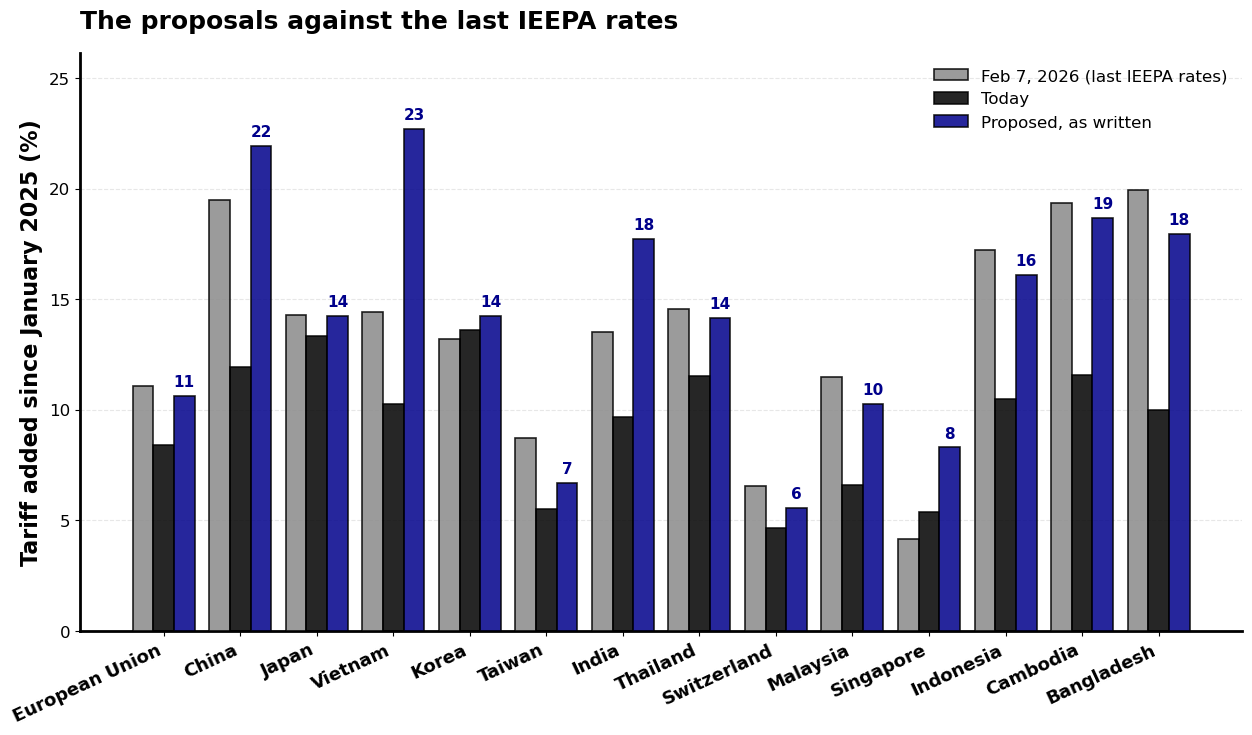

       economy  Feb 7 2026    today  proposed  proposed - IEEPA
European Union       11.07     8.40     10.60             -0.47
         China       19.49    11.94     21.95              2.45
         Japan       14.28    13.33     14.23             -0.05
       Vietnam       14.42    10.25     22.71              8.30
         Korea       13.20    13.61     14.22              1.01
        Taiwan        8.73     5.49      6.68             -2.05
         India       13.51     9.65     17.73              4.23
      Thailand       14.55    11.54     14.14             -0.41
   Switzerland        6.55     4.63      5.54             -1.01
      Malaysia       11.48     6.61     10.27             -1.21
     Singapore        4.15     5.36      8.29              4.14
     Indonesia       17.24    10.50     16.11             -1.13
      Cambodia       19.33    11.55     18.66             -0.67
    Bangladesh       19.94    10.00     17.96             -1.98

national: Feb 7, 2026 14.28%   today 11

In [10]:
ieepa = published[published.date == IEEPA_DATE].set_index('country_name')['effective tariff']
_nm = dict(zip(country_list.CTY_CODE, country_list.CTY_NAME))
G = S[S.targeted].copy()
G['ieepa'] = G.code.map(_nm).map(ieepa)
G = G.sort_values('imports', ascending=False).reset_index(drop=True)

x = np.arange(len(G)); w = 0.27
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.bar(x - w, G['ieepa'], w, color=PALETTE['ieepa'], edgecolor='black', linewidth=1.2,
       zorder=3, alpha=0.85, label='Feb 7, 2026 (last IEEPA rates)')
ax.bar(x, G['base'], w, color=PALETTE['now'], edgecolor='black', linewidth=1.2,
       zorder=3, alpha=0.85, label='Today')
bp = ax.bar(x + w, G['proposed'], w, color=PALETTE['proposed'], edgecolor='black', linewidth=1.2,
            zorder=3, alpha=0.85, label='Proposed, as written')
for b_, v in zip(bp, G['proposed']):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.3, f'{v:.0f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color=PALETTE['proposed'])
ax.set_xticks(x); ax.set_xticklabels(G['name'], rotation=25, ha='right', fontsize=13)
for lab in ax.get_xticklabels():
    lab.set_fontweight('bold')
ax.set_ylabel('Tariff added since January 2025 (%)')
ax.set_ylim(0, max(G[['ieepa', 'base', 'proposed']].max()) * 1.15)
ax.set_title('The proposals against the last IEEPA rates', loc='left', pad=18)
ax.legend(loc='upper right', fontsize=12)
ax.grid(axis='y')
plt.savefig(figfile + 'secp-vs-ieepa.png')
plt.savefig(figfile + 'secp-vs-ieepa.pdf')
plt.show()

cmp_ = G[['name', 'ieepa', 'base', 'proposed']].copy()
cmp_['proposed - IEEPA'] = cmp_['proposed'] - cmp_['ieepa']
cmp_.columns = ['economy', 'Feb 7 2026', 'today', 'proposed', 'proposed - IEEPA']
print(cmp_.to_string(index=False, float_format=lambda v: f'{v:8.2f}'))
print(f"\nnational: Feb 7, 2026 {ieepa_nat:.2f}%   today {NAT['base']:.2f}%   proposed {NAT['proposed']:.2f}%")

# What the result depends on

Four choices sit behind the headline. The first two are open questions the final notices
will answer; the last two are modeling choices.

In [11]:
def econ(code, col):
    return S.loc[S.code == code, col].iloc[0]

d0 = NAT['proposed'] - NAT['base']
print(f"National step as written: {d0:+.2f} pts ({NAT['base']:.2f}% -> {NAT['proposed']:.2f}%)\n")

print("1. Which rate applies")
print(f"   India 17, Singapore 10, Vietnam 20 (agreements): national {NAT['agreement']-NAT['base']:+.2f}")
for c in ('5520', '5330', '5590'):
    print(f"      {TARGETS[c]:10s} step {econ(c,'proposed')-econ(c,'base'):+6.2f} as written, "
          f"{econ(c,'agreement')-econ(c,'base'):+6.2f} with an agreement")
print(f"   every stated alternative: national {NAT['alternative']-NAT['base']:+.2f} "
      f"(China alone {(econ('5700','alternative')-econ('5700','base'))*econ('5700','imports')/S['imports'].sum():+.2f})")

print("\n2. China's Section 232 goods")
print(f"   covered, as written: China {econ('5700','proposed')-econ('5700','base'):+.2f}, national {d0:+.2f}")
print(f"   carved out:          China {econ('5700','proposed_c232')-econ('5700','base'):+.2f}, "
      f"national {NAT['proposed_c232']-NAT['base']:+.2f}")

print("\n3. Korea: flat (modeled) or net of MFN")
print(f"   flat: Korea {econ('5800','proposed')-econ('5800','base'):+.2f};  netted: "
      f"{econ('5800','korea_net')-econ('5800','base'):+.2f};  national difference "
      f"{NAT['korea_net']-NAT['proposed']:+.3f}")

print("\n4. Country-specific exemptions (Part II), modeled vs ignored")
for c in sorted(SECP_PART_II, key=lambda c: econ(c, 'proposed') - econ(c, 'no_lists')):
    print(f"   {TARGETS[c]:15s} step {econ(c,'proposed')-econ(c,'base'):+6.2f} modeled, "
          f"{econ(c,'no_lists')-econ(c,'base'):+6.2f} ignored")
print(f"   national difference {NAT['no_lists']-NAT['proposed']:+.3f}")

National step as written: +2.89 pts (11.46% -> 14.36%)

1. Which rate applies
   India 17, Singapore 10, Vietnam 20 (agreements): national +2.37
      Vietnam    step +12.46 as written,  +4.15 with an agreement
      India      step  +8.08 as written,  +3.77 with an agreement
      Singapore  step  +2.93 as written,  +0.00 with an agreement
   every stated alternative: national +6.92 (China alone +4.44)

2. China's Section 232 goods
   covered, as written: China +10.01, national +2.89
   carved out:          China +6.23, national +2.39

3. Korea: flat (modeled) or net of MFN
   flat: Korea +0.61;  netted: +0.38;  national difference -0.010

4. Country-specific exemptions (Part II), modeled vs ignored
   Indonesia       step  +5.60 modeled,  +6.34 ignored
   Malaysia        step  +3.66 modeled,  +3.72 ignored
   Cambodia        step  +7.11 modeled,  +7.14 ignored
   European Union  step  +2.20 modeled,  +2.22 ignored
   Switzerland     step  +0.91 modeled,  +0.92 ignored
   Taiwan      

## What else is scheduled first

The final action cannot come before the January 25, 2027 hearing. One step already in the
law lands before then: on January 1, 2027 the Section 232 rates on upholstered furniture
and kitchen cabinets rise (Proclamation 10976, as amended). Both dates are in the
published series: January 1, 2027 as scheduled law, and February 1, 2027 as the assumed
start of the proposals. The cell below rebuilds both numbers and checks them against the
published file.

In [12]:
def national_at(date, actions=None):
    tot = 0.0
    for _, c in country_list.iterrows():
        tot += rate(c['CTY_CODE'], actions, date) * _imp(c['CTY_CODE'])['imports'].sum()
    return tot / (S['imports'].sum() * 1e9) + MFN_BASELINE

jan1 = national_at('2027-01-01')
ph = pd.Timestamp(SECP_301_EFFECTIVE_DATE)
# With the action live, the registry already holds it from the assumed date.
with_secp = national_at(ph, TARIFF_ACTIONS if SECP_301_LIVE else TARIFF_ACTIONS + secp_actions())
print(f"today ({AS_OF.date()}):                         {NAT['base']:.2f}%")
print(f"Jan 1, 2027, timber step-up only:            {jan1:.2f}%  ({jan1 - NAT['base']:+.3f})")
print(f"assumed date {ph.date()}, proposals as written:     {with_secp:.2f}%  "
      f"({with_secp - jan1:+.2f} from the excess-capacity action)")
if SECP_301_LIVE:
    for d, v in [(pd.Timestamp('2027-01-01'), jan1), (ph, with_secp)]:
        assert abs(v - _daily.loc[d, 'import_weighted_avg_tariff']) < 1e-9, d
    print("both match daily-tariff-latest-data.csv")

today (2026-10-30):                         11.46%
Jan 1, 2027, timber step-up only:            11.50%  (+0.035)
assumed date 2027-02-01, proposals as written:     14.39%  (+2.89 from the excess-capacity action)
both match daily-tariff-latest-data.csv


## Summary

**What it is.** A proposal, not an action: USTR found the practices of 14 economies
actionable under Section 301(b) and proposed tariffs "up to" a rate on all of each
economy's goods, net of the forced-labor duty already in place. Section 232 goods and a
long product annex are exempt (for China the annex goods pay a lower rate instead).

**What it would do.** As written it lifts the national average by about 2.9 points, to
roughly where it stood before the Supreme Court ended the IEEPA tariffs. Vietnam, China,
India, Bangladesh and Cambodia move most. The five economies with framework deals and
MFN-netted rates move little.

**What is still open.**

1. *The rates.* All are ceilings. Agreements with India, Singapore and Vietnam would take
   about half a point off the national step; the stated alternatives would more than double
   it, mostly through China at 40%.
2. *China and Section 232.* Whether the China duty reaches goods already under Section 232
   is worth half a point nationally. The notice is silent.
3. *Timing.* No effective date. Comments close January 5, 2027; the hearing is January 25.
   The published series assumes February 1, 2027.
4. *Mexico and Norway.* No determination yet.

**Caveats.** Statutory rates on a fixed 2024 basket, as everywhere in the tracker. Exemptions
that depend on end use (pharmaceutical, civil aircraft) are applied by whole tariff code.
Medium and heavy vehicles, semiconductors and patented pharmaceuticals are exempt Section
232 sectors that the model does not identify, so their goods take the new duty when they
should not. Korea is modeled flat although its notice says "net of MFN", as for the labor
duty.